# Домашнее задание 3. Градиентный спуск, Ньютон, BFGS: реализация и сравнение

**Выдано:** 7 октября 2026. **Срок сдачи:** 21 октября 2026 (до начала занятия). **Максимум:** 10 баллов (+1 бонус).

**Как сдавать.** Работа сдаётся в ваш личный закрытый репозиторий `optimisation-misis-2026/numopt-<ваш логин>`: его видите только вы и преподаватель, приглашение приходит на почту, привязанную к GitHub. Этот ноутбук уже лежит там как `hw3/homework.ipynb`. Заполните его (ответы на теоретические вопросы — в markdown-ячейках, формулы в $\LaTeX$; код — в code-ячейках), выполните целиком (`Kernel → Restart Kernel and Run All Cells`) и загрузите обратно в папку `hw3/` под тем же именем (на github.com: *Add file → Upload files*); пошагово — в [инструкции](https://github.com/IlyaChichkanov/Numerical-Optimization/blob/main/CONTRIBUTING.md). Если вы уже сдали ДЗ 3 pull request'ом, ничего делать не нужно — работа засчитана. Задачи можно обсуждать, но текст и код пишутся самостоятельно; своё решение никому не показывайте.

**Материал:** лекция 4 ([конспект](https://github.com/IlyaChichkanov/Numerical-Optimization/blob/main/lectures/lecture04/lecture04.md)) и лекция 5 ([конспект](https://github.com/IlyaChichkanov/Numerical-Optimization/blob/main/lectures/lecture05/lecture05.md), [демо](https://github.com/IlyaChichkanov/Numerical-Optimization/blob/main/lectures/lecture05/demo05.ipynb), [семинар](https://github.com/IlyaChichkanov/Numerical-Optimization/blob/main/lectures/lecture05/seminar05.ipynb)). Ничего сверх лекций не требуется. Ориентировочное время — 3–4 часа.

**Устройство задания.** Обвязка — функции Розенброка, цепь, данные синуса, рисовальщики — дана готовой в ячейке ниже; вы пишете только то, что составляет метод: направление, выбор длины шага, обновление матрицы, шаг Гаусса–Ньютона. Под каждым заданием стоит проверка (`assert`), которая ловит смысл: если она прошла, можно идти дальше. Все методы работают с одними и теми же параметрами, чтобы числа совпали с конспектом: backtracking по Армихо с $c=10^{-4}$ от $\alpha=1$ делением пополам, останов по $\lVert\nabla f\rVert\le10^{-6}$ (у Ньютона — $10^{-10}$).

Запуск: `uv sync` в корне репозитория, затем `uv run jupyter lab`; в Colab ничего ставить не нужно.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, least_squares

rng = np.random.default_rng(2026)   # не меняйте seed: данные должны совпадать у всех

BLUE, ORANGE, AQUA, RED, VIOLET, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#4a3aa7", "#8a8985", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2, "legend.frameon": False})


# ---------------------------------------------------------------- задачи (даны готовыми)
def rosen(x):
    return (1 - x[0]) ** 2 + 100 * (x[1] - x[0] ** 2) ** 2


def rosen_grad(x):
    return np.array([-2 * (1 - x[0]) - 400 * x[0] * (x[1] - x[0] ** 2), 200 * (x[1] - x[0] ** 2)])


def rosen_hess(x):
    return np.array([[2 - 400 * x[1] + 1200 * x[0] ** 2, -400 * x[0]], [-400 * x[0], 200.0]])


X0_ROSEN = np.array([-1.2, 1.0])


def make_chain(N, D=70.0, g=9.81):
    """Цепь без пола (лекция 1, §7.3; лекция 4): E(v) = 1/2 v^T H v + b^T v + const.
    Возвращает (energy, grad_E, H, b, v0): функция, градиент, гессиан, линейный член, старт (прямая между концами)."""
    m = 4.0 / N
    K = 2 * np.eye(N) - np.eye(N, k=1) - np.eye(N, k=-1)
    H = np.kron(np.eye(2), D * K)
    b = np.zeros(2 * N)
    b[0] -= D * (-2.0); b[N - 1] -= D * 2.0; b[N] -= D * 1.0; b[2 * N - 1] -= D * 1.0; b[N:] += m * g
    v0 = np.r_[np.linspace(-2, 2, N + 2)[1:-1], np.ones(N)]

    def energy(v):
        y, z = np.r_[-2.0, v[:N], 2.0], np.r_[1.0, v[N:], 1.0]
        return 0.5 * D * np.sum(np.diff(y) ** 2 + np.diff(z) ** 2) + m * g * np.sum(z[1:-1])

    return energy, (lambda v: H @ v + b), H, b, v0


# данные задачи 2(б) ДЗ 2: y = 2 sin(3t + 0.7) + шум, 60 точек, те же 20 стартов
data_rng = np.random.default_rng(2026)
t_data = np.sort(data_rng.uniform(0, 2 * np.pi, 60))
y_data = 2.0 * np.sin(3.0 * t_data + 0.7) + 0.2 * data_rng.standard_normal(60)
starts = data_rng.uniform(-5, 5, (20, 3))
X0_SINE = np.array([1.0, 3.0, 0.0])


def sine_resid(x):
    """Невязки модели x1 sin(x2 t + x3) на данных."""
    return x[0] * np.sin(x[1] * t_data + x[2]) - y_data


def sine_jac(x):
    """Якобиан невязок (60 x 3): столбцы — производные по амплитуде, частоте, фазе."""
    s, c = np.sin(x[1] * t_data + x[2]), np.cos(x[1] * t_data + x[2])
    return np.c_[s, x[0] * t_data * c, x[0] * c]


def sine_f(x):
    r = sine_resid(x); return 0.5 * (r @ r)


def sine_grad(x):
    return sine_jac(x).T @ sine_resid(x)


# ---------------------------------------------------------------- рисовальщики (принимают ax=None, возвращают ax)
def plot_rosen_path(paths, labels=None, ax=None, xlim=(-2.2, 2.2), ylim=(-3.5, 3.2), every=50):
    """Линии уровня Розенброка и пути методов; длинные пути прореживаются (каждая every-я точка после 30-й)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 5))
    X, Y = np.meshgrid(np.linspace(*xlim, 400), np.linspace(*ylim, 400))
    ax.contour(X, Y, (1 - X) ** 2 + 100 * (Y - X ** 2) ** 2, levels=np.logspace(-1, 3.3, 14), colors=[GRAY], linewidths=0.7)
    colors = [BLUE, ORANGE, AQUA, VIOLET, RED]
    for i, p in enumerate(paths):
        pp = p if len(p) <= 60 else np.r_[p[:30], p[30::every]]
        ax.plot(pp[:, 0], pp[:, 1], "-o", ms=3 if len(p) > 60 else 4.5, lw=1.3, color=colors[i % 5], label=None if labels is None else labels[i])
    ax.plot(1, 1, "*", ms=13, color=RED, mec="white", zorder=7)
    ax.set(xlim=xlim, ylim=ylim, xlabel="$x_1$", ylabel="$x_2$"); ax.grid(False)
    if labels is not None:
        ax.legend(loc="upper left", fontsize=8)
    return ax


def plot_grad_norms(gnorms, labels=None, ax=None):
    """log10 нормы градиента по итерациям для нескольких методов (ось итераций логарифмическая)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6.5, 4.2))
    colors = [BLUE, ORANGE, AQUA, VIOLET, RED]
    for i, gn in enumerate(gnorms):
        ax.plot(np.arange(1, len(gn) + 1), np.log10(np.asarray(gn) + 1e-17), "-o" if len(gn) < 60 else "-", ms=3.5, lw=1.4, color=colors[i % 5], label=None if labels is None else labels[i])
    ax.set_xscale("log"); ax.set(xlabel="итерация $k$ (лог. шкала)", ylabel="$\\log_{10}\\Vert\\nabla f(x_k)\\Vert$")
    if labels is not None:
        ax.legend(fontsize=8)
    return ax


print("данные синуса:", t_data.shape, " стартов ДЗ 2:", len(starts), " f в старте (1, 3, 0):", round(sine_f(X0_SINE), 3))

данные синуса: (60,)  стартов ДЗ 2: 20  f в старте (1, 3, 0): 33.867


## Задача 1. Теория (4 балла)

По 1 баллу за пункт. Нужны выкладки, а не только ответ; численная проверка приветствуется, но текстом объясните, почему так.

**(а) Один шаг Ньютона.** $f(x)=x_1^2+2x_2^2+x_1x_2-4x_1-7x_2$. Из точки $x_0=(0,0)$ сделайте один шаг Ньютона руками: выпишите $\nabla f(x_0)$, $\nabla^2f$, решите систему $Hp=-g$ и проверьте, что в новой точке $\nabla f=0$. Почему здесь хватило одной итерации и какое свойство функции за это отвечает?

**(б) Цифры удваиваются.** Метод Ньютона для $F(x)=x^2-a$ даёт $x_{k+1}=\tfrac12(x_k+a/x_k)$. Покажите, что ошибка $e_k=x_k-\sqrt a$ удовлетворяет $e_{k+1}=\dfrac{e_k^2}{2x_k}$. Для $a=3$, $x_0=2$ выпишите $x_1,x_2,x_3$ и ошибки; сколько верных цифр прибавляет каждый шаг?

**(в) Секущее уравнение для $B$.** Обновление BFGS для самого гессиана (не обратного): $B_{k+1}=B_k-\dfrac{B_ks_ks_k^\top B_k}{s_k^\top B_ks_k}+\dfrac{y_ky_k^\top}{y_k^\top s_k}$. Проверьте подстановкой, что $B_{k+1}s_k=y_k$. Почему для этого нужно $y_k^\top s_k\ne0$, и что это условие означает для функции?

**(г) Что отбрасывает Гаусс–Ньютон.** $f(x)=\tfrac12\lVert r(x)\rVert^2$, $r(x)=\big(x_1-2,\ x_2-1,\ x_1x_2-1\big)$. Выпишите $J$, $J^\top J$ и полный гессиан $\nabla^2f=J^\top J+\sum_ir_i\nabla^2r_i$. Где отброшенный член равен нулю? Есть ли у этой задачи точка, где все невязки нулевые, и что это значит для сходимости Гаусса–Ньютона рядом с ней?

**(а)**

**Ответ:** $x_1 = \big(\tfrac97,\ \tfrac{10}7\big)$.

$$\nabla f = \begin{pmatrix} 2x_1 + x_2 - 4 \\ x_1 + 4x_2 - 7 \end{pmatrix}, \qquad \nabla f(x_0) = \begin{pmatrix} -4 \\ -7 \end{pmatrix}, \qquad \nabla^2 f = \begin{pmatrix} 2 & 1 \\ 1 & 4 \end{pmatrix}.$$

$$p = -(\nabla^2 f)^{-1}\nabla f(x_0) = \frac17\begin{pmatrix} 4 & -1 \\ -1 & 2 \end{pmatrix}\begin{pmatrix} 4 \\ 7 \end{pmatrix} = \frac17\begin{pmatrix} 9 \\ 10 \end{pmatrix}, \qquad \nabla f(x_1) = \Big(\frac{18 + 10 - 28}{7},\ \frac{9 + 40 - 49}{7}\Big) = (0,\ 0).$$

Одного шага хватило, потому что $f$ квадратичная: её разложение Тейлора второго порядка точное, и минимум модели Ньютона — минимум самой $f$.

In [2]:
H_a = np.array([[2.0, 1.0], [1.0, 4.0]])
grad_a = lambda x: np.array([2 * x[0] + x[1] - 4, x[0] + 4 * x[1] - 7])

x0_a = np.zeros(2)
x1_a = x0_a + np.linalg.solve(H_a, -grad_a(x0_a))
print("x1 =", x1_a, " совпадает с (9/7, 10/7):", np.allclose(x1_a, [9 / 7, 10 / 7]))
print("градиент в x1:", grad_a(x1_a))
print("собственные числа гессиана:", np.linalg.eigvalsh(H_a))

x1 = [1.28571429 1.42857143]  совпадает с (9/7, 10/7): True
градиент в x1: [0. 0.]
собственные числа гессиана: [1.58578644 4.41421356]


**(б)**

**Ответ:** каждый шаг удваивает число верных цифр.

$$e_{k+1} = \frac12\Big(x_k + \frac{a}{x_k}\Big) - \sqrt a = \frac{x_k^2 - 2\sqrt a\,x_k + a}{2x_k} = \frac{e_k^2}{2x_k}.$$

| $k$ | $x_k$ | $e_k$ | верных цифр |
|---|---|---|---|
| 0 | $2$ | $2.7 \cdot 10^{-1}$ | 0 |
| 1 | $7/4$ | $1.8 \cdot 10^{-2}$ | 2 |
| 2 | $97/56$ | $9.2 \cdot 10^{-5}$ | 4 |
| 3 | $18817/10864$ | $2.4 \cdot 10^{-9}$ | 8 |

In [3]:
from fractions import Fraction

x = Fraction(2)
for k in range(4):
    e = float(x) - np.sqrt(3)
    pred = "" if k == 0 else f", e_(k-1)^2 / (2 x_(k-1)) = {e_prev ** 2 / (2 * x_prev):.3e}"
    print(f"x{k} = {str(x):>11} = {float(x):.13f}, e{k} = {e:.3e}{pred}")
    x_prev, e_prev = float(x), e
    x = (x + 3 / x) / 2
print(f"sqrt(3)            = {np.sqrt(3):.13f}")

x0 =           2 = 2.0000000000000, e0 = 2.679e-01
x1 =         7/4 = 1.7500000000000, e1 = 1.795e-02, e_(k-1)^2 / (2 x_(k-1)) = 1.795e-02
x2 =       97/56 = 1.7321428571429, e2 = 9.205e-05, e_(k-1)^2 / (2 x_(k-1)) = 9.205e-05
x3 = 18817/10864 = 1.7320508100147, e3 = 2.446e-09, e_(k-1)^2 / (2 x_(k-1)) = 2.446e-09
sqrt(3)            = 1.7320508075689


**(в)**

**Ответ:**

$$B_{k+1}s_k = B_ks_k - B_ks_k\,\frac{s_k^\top B_ks_k}{s_k^\top B_ks_k} + y_k\,\frac{y_k^\top s_k}{y_k^\top s_k} = y_k.$$

Последняя дробь сокращается, только если $y_k^\top s_k \ne 0$: иначе формула делит на ноль. Для функции

$$y_k^\top s_k = \big(\nabla f(x_{k+1}) - \nabla f(x_k)\big)^\top s_k = \int_0^1 s_k^\top \nabla^2 f(x_k + \tau s_k)\, s_k\, d\tau$$

— это средняя кривизна $f$ вдоль шага. Условие $y_k^\top s_k \ne 0$ значит, что наклон $f$ вдоль шага изменился, то есть кривизна вдоль $s_k$ ненулевая.

**(г)**

**Ответ:**

$$J = \begin{pmatrix} 1 & 0 \\ 0 & 1 \\ x_2 & x_1 \end{pmatrix}, \qquad J^\top J = \begin{pmatrix} 1 + x_2^2 & x_1x_2 \\ x_1x_2 & 1 + x_1^2 \end{pmatrix}, \qquad \nabla^2 f = J^\top J + (x_1x_2 - 1)\begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix}.$$

Отброшенный член равен нулю на гиперболе $x_1x_2 = 1$.

Точки с нулевыми невязками нет: из $r_1 = r_2 = 0$ получаем $x = (2, 1)$, а там $r_3 = 1$. Значит, в минимуме отброшенный член не нулевой, $J^\top J \ne \nabla^2 f$, и Гаусс–Ньютон сходится только линейно (отношение ошибок $\approx 0.146$ в ячейке ниже), а не квадратично.

In [4]:
r_g = lambda x: np.array([x[0] - 2, x[1] - 1, x[0] * x[1] - 1])
J_g = lambda x: np.array([[1.0, 0.0], [0.0, 1.0], [x[1], x[0]]])
hess_g = lambda x: J_g(x).T @ J_g(x) + r_g(x)[2] * np.array([[0.0, 1.0], [1.0, 0.0]])

# формула гессиана против конечных разностей градиента J^T r в случайной точке
f_g = lambda x: 0.5 * r_g(x) @ r_g(x)
xt, h = rng.standard_normal(2), 1e-6
fd = np.array([(J_g(xt + h * e).T @ r_g(xt + h * e) - J_g(xt - h * e).T @ r_g(xt - h * e)) / (2 * h) for e in np.eye(2)])
print("гессиан по формуле совпадает с конечными разностями:", np.allclose(hess_g(xt), fd, atol=1e-6))

# чистый Гаусс–Ньютон из (0, 0) (функция gauss_newton появится только в задаче 2(в))
path_g = [np.zeros(2)]
for _ in range(40):
    x = path_g[-1]
    path_g.append(x + np.linalg.lstsq(J_g(x), -r_g(x), rcond=None)[0])
path_g = np.array(path_g); x_g, k_g = path_g[-1], len(path_g) - 1
print(f"\nГаусс–Ньютон из (0, 0) после {k_g} шагов: x* = {x_g.round(4)}, невязки r(x*) = {r_g(x_g).round(4)}, f* = {f_g(x_g):.4f}")
err_g = np.linalg.norm(path_g - x_g, axis=1)
print("отношения ошибок e_(k+1)/e_k:", (err_g[1:10] / err_g[:9]).round(3))

гессиан по формуле совпадает с конечными разностями: True

Гаусс–Ньютон из (0, 0) после 40 шагов: x* = [1.8767 0.6362], невязки r(x*) = [-0.1233 -0.3638  0.1939], f* = 0.0926
отношения ошибок e_(k+1)/e_k: [0.194 0.138 0.16  0.136 0.149 0.145 0.147 0.146 0.146]


## Задача 2. Практика (6 баллов)

### (а) Три кирпича методов (2 балла)

Метод Ньютона с backtracking и BFGS собираются из трёх частей; каждую пишете отдельно, под каждой — проверка. Сигнатуры не меняйте: ниже готовые циклы `newton_damped` и `bfgs` используют именно их.

**TODO 1 — направление Ньютона.** `newton_direction(g, H)` возвращает $p$ — решение $Hp=-g$. Если $g^\top p\ge0$ (направление не спуск — гессиан индефинитен), верните вместо него решение системы с регуляризованной матрицей $H+(\lvert\lambda_{\min}\rvert+10^{-3})I$.

In [5]:
def newton_direction(g, H):
    """Направление Ньютона p = -H^{-1} g; при g^T p >= 0 — регуляризация H + (|lambda_min| + 1e-3) I."""
    p = np.linalg.solve(H, -g)
    if g @ p >= 0:
        lam_min = np.linalg.eigvalsh(H)[0]
        p = np.linalg.solve(H + (abs(lam_min) + 1e-3) * np.eye(len(g)), -g)
    return p

In [6]:
# проверка TODO 1: на квадратичной из задачи 1(а) один шаг попадает в минимум; при индефинитном H направление — спуск
H_q = np.array([[2.0, 1.0], [1.0, 4.0]]); g_q = np.array([-4.0, -7.0])
assert np.allclose(newton_direction(g_q, H_q), [9 / 7, 10 / 7]), "на квадратичной 1(а) шаг Ньютона должен быть (9/7, 10/7): проверьте знак в решении системы"
H_ind = np.diag([1.0, -1.0]); g_ind = np.array([0.0, 1.0])
assert g_ind @ newton_direction(g_ind, H_ind) < 0, "при индефинитном H и g = (0, 1) чистый шаг (0, 1) идёт вверх — нужна регуляризация"
print("TODO 1: ok")

TODO 1: ok


**TODO 2 — длина шага по Армихо.** `armijo(f, x, p, g, c=1e-4)` возвращает $\alpha$: начинаем с $\alpha=1$ и делим пополам, пока не выполнено $f(x+\alpha p)\le f(x)+c\,\alpha\,g^\top p$ (лекция 4, §4.5; лекция 5, §3.4).

In [7]:
def armijo(f, x, p, g, c=1e-4):
    """Backtracking: alpha = 1, делим пополам до выполнения условия Армихо."""
    alpha, fx, slope = 1.0, f(x), g @ p
    while f(x + alpha * p) > fx + c * alpha * slope:
        alpha /= 2
    return alpha

In [8]:
# проверка TODO 2: на f = 1/2 (x1^2 + 10 x2^2) из (3, 1) вдоль -g первый принятый шаг — ровно 1/8 (лекция 4, картинка 03)
Q2 = np.diag([1.0, 10.0]); f2 = lambda x: 0.5 * x @ Q2 @ x
x2 = np.array([3.0, 1.0]); g2 = Q2 @ x2
a = armijo(f2, x2, -g2, g2)
assert abs(a - 0.125) < 1e-12, f"ожидался шаг 1/8, получен {a}: делите пополам, начиная с 1, и проверяйте условие с c * alpha * g^T p"
assert armijo(f2, x2, -g2 * 1e-3, g2) == 1.0, "короткое направление должно приниматься целиком (alpha = 1)"
print("TODO 2: ok")

TODO 2: ok


**TODO 3 — обновление BFGS.** `bfgs_update(H, s, y)` возвращает $H_{k+1}=(I-\rho sy^\top)H(I-\rho ys^\top)+\rho ss^\top$, $\rho=1/(y^\top s)$ (лекция 5, §4.3).

In [9]:
def bfgs_update(H, s, y):
    """Обновление обратного гессиана BFGS по паре (s, y)."""
    rho = 1.0 / (y @ s)
    V = np.eye(len(s)) - rho * np.outer(y, s)
    return V.T @ H @ V + rho * np.outer(s, s)

In [10]:
# проверка TODO 3: секущее уравнение, симметрия, H > 0; на квадратичной kappa = 50 из (50, 1) с точным шагом два обновления дают H_2 = Q^{-1} (упражнение 11.5)
Hs = np.eye(3); s_, y_ = np.array([1.0, -2.0, 0.5]), np.array([0.5, -1.0, 2.0])
Hn = bfgs_update(Hs, s_, y_)
assert np.allclose(Hn @ y_, s_), "секущее уравнение H_{k+1} y = s нарушено: проверьте порядок s и y в формуле"
assert np.allclose(Hn, Hn.T) and np.all(np.linalg.eigvalsh(Hn) > 0), "H_{k+1} должна быть симметричной и положительно определённой при s^T y > 0"
Q50 = np.diag([1.0, 50.0]); xq = np.array([50.0, 1.0]); Hq = np.eye(2)
for _ in range(2):
    gq = Q50 @ xq; pq = -Hq @ gq; aq = -(gq @ pq) / (pq @ Q50 @ pq)      # точный шаг на квадратичной
    sq = aq * pq; xq = xq + sq; Hq = bfgs_update(Hq, sq, Q50 @ sq)
assert np.allclose(Hq, np.linalg.inv(Q50), atol=1e-10) and np.allclose(xq, 0, atol=1e-9), "после двух обновлений на квадратичной 2x2 должно получиться H_2 = Q^{-1} = diag(1, 0.02) и x_2 = 0"
print("TODO 3: ok;  H_2 =", Hq.round(6).tolist())

TODO 3: ok;  H_2 = [[1.0, 0.0], [0.0, 0.02]]


Сборка методов из кирпичей — дана готовой (сравните с лекцией: это ровно `newton_damped` и `bfgs` из `l5helpers.py`). `gd` — градиентный спуск с backtracking из лекции 4, тоже через ваш `armijo`.

In [11]:
def gd(f, grad, x0, alpha=None, tol=1e-6, maxit=100_000):
    """Градиентный спуск: alpha=None — backtracking по Армихо, иначе постоянный шаг. Возвращает (x, итераций, путь, нормы градиента)."""
    x = np.asarray(x0, float).copy(); path = [x.copy()]; gnorm = []
    for k in range(maxit):
        g = grad(x); gnorm.append(np.linalg.norm(g))
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        a = armijo(f, x, -g, g) if alpha is None else alpha
        x = x - a * g; path.append(x.copy())
    return x, maxit, np.array(path), np.array(gnorm)


def newton_damped(f, grad, hess, x0, tol=1e-10, maxit=200):
    """Ньютон с backtracking. Возвращает (x, итераций, путь, нормы градиента)."""
    x = np.asarray(x0, float).copy(); path = [x.copy()]; gnorm = []
    for k in range(maxit):
        g = grad(x); gnorm.append(np.linalg.norm(g))
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        p = newton_direction(g, hess(x))
        x = x + armijo(f, x, p, g) * p; path.append(x.copy())
    return x, maxit, np.array(path), np.array(gnorm)


def bfgs(f, grad, x0, tol=1e-6, maxit=10_000):
    """BFGS с H_0 = I и backtracking по Армихо. Возвращает (x, итераций, путь, нормы градиента)."""
    x = np.asarray(x0, float).copy(); H = np.eye(len(x)); g = grad(x); path = [x.copy()]; gnorm = [np.linalg.norm(g)]
    for k in range(maxit):
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        p = -H @ g
        s = armijo(f, x, p, g) * p; x_new = x + s; g_new = grad(x_new); y = g_new - g
        if s @ y > 1e-12:                                   # условие кривизны, иначе H не трогаем
            H = bfgs_update(H, s, y)
        x, g = x_new, g_new; path.append(x.copy()); gnorm.append(np.linalg.norm(g))
    return x, maxit, np.array(path), np.array(gnorm)


print("методы собраны")

методы собраны


### (б) Розенброк и цепь: сравнение (2 балла)

1. Запустите три метода на Розенброке из $(-1.2,\,1)$ (спуск и BFGS — до $\lVert\nabla f\rVert\le10^{-6}$, Ньютон — до $10^{-10}$). Напечатайте таблицу: метод, число итераций, число вычислений $f$ (добавьте счётчик — например, обёрткой вокруг `rosen`), конечная точка. Ожидаемые числа конспекта — $13\,756$, $22$, $34$; расхождение до $5\,\%$ допустимо.
2. Нарисуйте две картинки готовыми рисовальщиками: пути трёх методов на линиях уровня (`plot_rosen_path`) и $\log_{10}\lVert\nabla f(x_k)\rVert$ по итерациям (`plot_grad_norms`). Назовите по графику тип сходимости каждого метода (лекция 4, §6; лекция 5, §3–4).
3. Цепь $N=40$: спуск с постоянным шагом $1/L$ ($L=\lambda_{\max}(H)$) против одного шага Ньютона `v0 - solve(H, grad(v0))`: число итераций, энергия в конце, расхождение решений. Затем запустите **ваш** `bfgs` на цепи $N=10$ и $N=20$ с `maxit=10_000`: сошёлся ли он? Объясните результат одним абзацем через упражнение 11.9 конспекта (что ломается у BFGS с одним лишь backtracking и что это лечит).

Критерии: полный балл — таблица с числами в пределах допуска, обе картинки, верно названные типы сходимости и внятное объяснение по цепи; половина — методы работают, но без анализа.

метод               итераций  вызовов f   конечная точка
градиентный спуск      13756     150555   (0.99999922, 0.99999843)
Ньютон (Армихо)           22         51   (1.00000000, 1.00000000)
BFGS                      34         87   (1.00000000, 0.99999999)


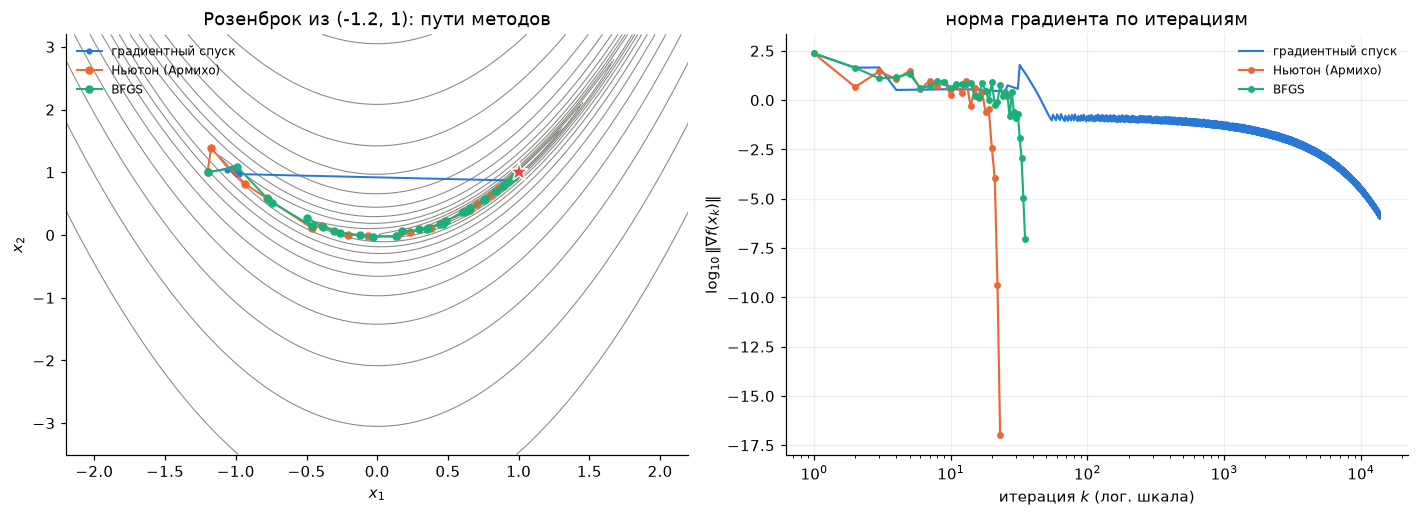

In [12]:
class Counted:
    """Обёртка вокруг f, считающая вызовы."""
    def __init__(self, f):
        self.f, self.n = f, 0

    def __call__(self, x):
        self.n += 1
        return self.f(x)


runs = {
    "градиентный спуск": lambda f: gd(f, rosen_grad, X0_ROSEN),
    "Ньютон (Армихо)": lambda f: newton_damped(f, rosen_grad, rosen_hess, X0_ROSEN),
    "BFGS": lambda f: bfgs(f, rosen_grad, X0_ROSEN),
}
res_rosen = {}
print(f"{'метод':<19}{'итераций':>9}{'вызовов f':>11}   конечная точка")
for name, run in runs.items():
    cf = Counted(rosen)
    x, k, path, gn = run(cf)
    res_rosen[name] = (path, gn)
    print(f"{name:<19}{k:>9}{cf.n:>11}   ({x[0]:.8f}, {x[1]:.8f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
plot_rosen_path([p for p, _ in res_rosen.values()], list(res_rosen), ax=axes[0])
axes[0].set_title("Розенброк из (-1.2, 1): пути методов")
plot_grad_norms([g for _, g in res_rosen.values()], list(res_rosen), ax=axes[1])
axes[1].set_title("норма градиента по итерациям")
plt.tight_layout(); plt.show()

**Ответ:**

1. Спуск — линейная сходимость: норма градиента убывает медленно и равномерно.
2. Ньютон — квадратичная: в конце обрыв.
3. BFGS — сверхлинейная: кривая загибается всё круче, но мягче, чем у Ньютона.

In [13]:
# цепь N = 40: спуск с шагом 1/L против одного шага Ньютона
energy40, grad40, H40, b40, v40 = make_chain(40)
v_gd, k_gd, _, _ = gd(energy40, grad40, v40, alpha=1 / np.linalg.eigvalsh(H40)[-1])
v_nt = v40 - np.linalg.solve(H40, grad40(v40))
print(f"спуск 1/L: {k_gd} итераций, E = {energy40(v_gd):.10f}")
print(f"Ньютон:    1 итерация,     E = {energy40(v_nt):.10f}")
print(f"||v_gd - v_nt|| = {np.linalg.norm(v_gd - v_nt):.1e}")

# наш bfgs на цепи N = 10 и N = 20
for N in [10, 20]:
    e_N, g_N, H_N, b_N, v0_N = make_chain(N)
    x, k, path, gn = bfgs(e_N, g_N, v0_N, maxit=10_000)
    print(f"\nN = {N}: {k} итераций, ||grad|| = {gn[-1]:.1e}")
    if k == 10_000:
        print(f"  последние ||s_k|| = {np.linalg.norm(np.diff(path[-4:], axis=0), axis=1)}")
        print(f"  E - E* = {e_N(x) - e_N(np.linalg.solve(H_N, -b_N)):.1e}, округление eps * E = {np.finfo(float).eps * e_N(x):.1e}")

спуск 1/L: 10575 итераций, E = 13.4417355854
Ньютон:    1 итерация,     E = 13.4417355854
||v_gd - v_nt|| = 2.4e-06

N = 10: 36 итераций, ||grad|| = 5.0e-09



N = 20: 10000 итераций, ||grad|| = 4.1e-06
  последние ||s_k|| = [0. 0. 0.]
  E - E* = 5.7e-14, округление eps * E = 9.9e-15


**Ответ:**

Цепь $N = 40$: спуск с шагом $1/L$ — $10\,575$ итераций, Ньютон — одна, энергия одинаковая, решения расходятся на $2.4 \cdot 10^{-6}$.

BFGS: при $N = 10$ сошёлся за $36$ итераций, при $N = 20$ не сошёлся: шаги обнулились при $\Vert\nabla E\Vert = 4 \cdot 10^{-6}$.

Армихо отсекает только слишком длинные шаги. У минимума $E - E^\ast$ — несколько единиц округления $E$, поэтому сравнение значений превращается в шум, и Армихо дробит шаг до нуля. Тогда $s^\top y \approx 0$, обновление пропускается, $H_k$ не меняется, и метод стоит. Условие Вольфе $\nabla f(x_k + \alpha p_k)^\top p_k \ge c_2\, g_k^\top p_k$ запрещает слишком короткие шаги и гарантирует $s^\top y > 0$, так что каждое обновление учит $H_k$ кривизне.

### (в) Гаусс–Ньютон на синусе из ДЗ 2 (2 балла)

**TODO 4 — шаг Гаусса–Ньютона.** Допишите в `gauss_newton` строку с направлением: $p$ — решение линейного МНК $\min_p\lVert Jp+r\rVert^2$ (`np.linalg.lstsq`). Длина шага — ваш `armijo` на $f=\tfrac12\lVert r\rVert^2$ (демпфированный Гаусс–Ньютон). Проверка под ячейкой: на **линейных** невязках $r=Ax-b$ метод обязан сойтись за одну итерацию к `lstsq`.

Затем:

1. Запустите из $(1,\,3,\,0)$: ожидается $7$ итераций и $f^\ast=1.1393$, $x^\ast\approx(2.10,\,2.997,\,0.700)$. Сравните с вашим `bfgs` на `sine_f` из того же старта (итерации и вызовы функции) и со спуском ($731$ итерация в конспекте).
2. Запустите из всех 20 стартов `starts` ДЗ 2 (`maxit=200`). Сколько стартов пришли к глобальному $f^\ast=1.1393$ (с точностью $10^{-6}$)? Нарисуйте данные и все 20 подогнанных кривых одной картинкой. Объясните в двух предложениях, почему быстрый локальный метод не отменяет мультистарт из ДЗ 2.

Критерии: полный балл — проверка на линейных невязках проходит, числа пункта 1 воспроизведены, картинка и объяснение; половина — метод сходится, но без сравнения или без мультистарта.

In [14]:
def gauss_newton(resid, jac, x0, tol=1e-6, maxit=100):
    """Демпфированный Гаусс–Ньютон для f = 1/2 ||r||^2. Возвращает (x, итераций, путь, нормы градиента)."""
    f = lambda x: 0.5 * np.sum(resid(x) ** 2)
    x = np.asarray(x0, float).copy(); path = [x.copy()]; gnorm = []
    for k in range(maxit):
        r, J = resid(x), jac(x); g = J.T @ r; gnorm.append(np.linalg.norm(g))
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        p = np.linalg.lstsq(J, -r, rcond=None)[0]           # шаг Гаусса–Ньютона — решение min ||J p + r||
        x = x + armijo(f, x, p, g) * p; path.append(x.copy())
    return x, maxit, np.array(path), np.array(gnorm)

In [15]:
# проверка TODO 4: линейные невязки r = A x - b — один шаг из любого старта даёт решение lstsq
A_lin = rng.standard_normal((30, 4)); b_lin = rng.standard_normal(30)
x_lin, k_lin, _, _ = gauss_newton(lambda x: A_lin @ x - b_lin, lambda x: A_lin, np.ones(4), tol=1e-10)
assert k_lin == 1 and np.allclose(x_lin, np.linalg.lstsq(A_lin, b_lin, rcond=None)[0]), "на линейных невязках Гаусс–Ньютон должен совпасть с lstsq за одну итерацию: проверьте знак (-r) и что p решает именно min ||J p + r||"
print("TODO 4: ok")

TODO 4: ok


Гаусс–Ньютон    7 итераций,    22 вызовов, f = 1.1393, x = [2.1014 2.9967 0.7003]
BFGS           12 итераций,    41 вызовов, f = 1.1393, x = [2.1014 2.9967 0.7003]
спуск         731 итераций,  8685 вызовов, f = 1.1393, x = [2.1014 2.9967 0.7003]

к f* = 1.1393 пришли 12 стартов из 20


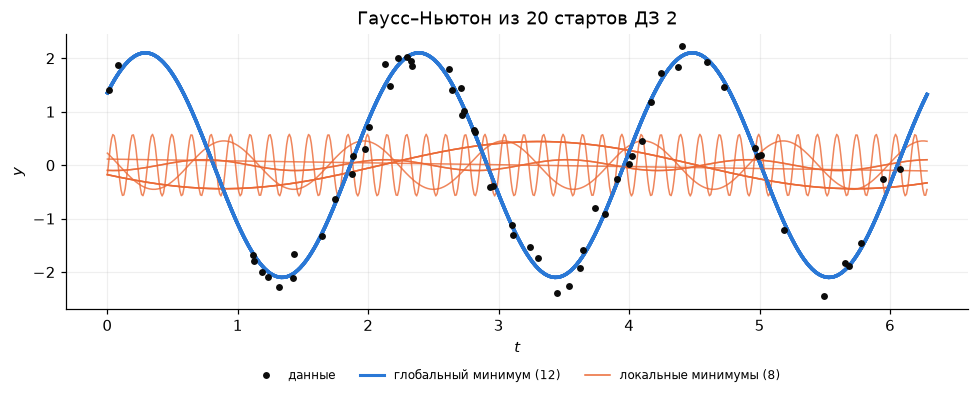

In [16]:
# пункт 1: Гаусс–Ньютон, BFGS и спуск из (1, 3, 0)
r_calls = Counted(sine_resid); x_gn, k_gn, _, _ = gauss_newton(r_calls, sine_jac, X0_SINE)
f_bf = Counted(sine_f); x_bf, k_bf, _, _ = bfgs(f_bf, sine_grad, X0_SINE)
f_sd = Counted(sine_f); x_sd, k_sd, _, _ = gd(f_sd, sine_grad, X0_SINE)
for name, k, n, x in [("Гаусс–Ньютон", k_gn, r_calls.n, x_gn), ("BFGS", k_bf, f_bf.n, x_bf), ("спуск", k_sd, f_sd.n, x_sd)]:
    print(f"{name:<13}{k:4d} итераций, {n:5d} вызовов, f = {sine_f(x):.4f}, x = {x.round(4)}")

# пункт 2: мультистарт из 20 стартов ДЗ 2
fits = [gauss_newton(sine_resid, sine_jac, s, maxit=200)[0] for s in starts]
f_fin = np.array([sine_f(x) for x in fits])
ok = np.abs(f_fin - f_fin.min()) < 1e-6
print(f"\nк f* = {f_fin.min():.4f} пришли {ok.sum()} стартов из {len(starts)}")

ts = np.linspace(0, 2 * np.pi, 600)
plt.figure(figsize=(9, 3.8))
for x, good in zip(fits, ok):
    plt.plot(ts, x[0] * np.sin(x[1] * ts + x[2]), color=BLUE if good else ORANGE, lw=2.2 if good else 1.0, alpha=0.6 if good else 0.8)
plt.plot(t_data, y_data, "o", ms=3.5, color=INK, zorder=5, label="данные")
plt.plot([], [], color=BLUE, lw=2, label=f"глобальный минимум ({ok.sum()})")
plt.plot([], [], color=ORANGE, lw=1, label=f"локальные минимумы ({(~ok).sum()})")
plt.xlabel("$t$"); plt.ylabel("$y$"); plt.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
plt.title("Гаусс–Ньютон из 20 стартов ДЗ 2"); plt.tight_layout(); plt.show()

**Ответ:**

1. Все три метода приходят в $x^\ast = (2.101,\ 2.997,\ 0.700)$, $f^\ast = 1.1393$: Гаусс–Ньютон за $7$ итераций и $22$ вызова, BFGS за $12$ и $41$, спуск за $731$ и $8685$.
2. К глобальному минимуму пришли $12$ стартов из $20$.

Быстрый метод ускоряет каждый старт, но не меняет того, куда старт приходит: это определяет невыпуклая $f$, а не метод. Поэтому мультистарт по-прежнему нужен.

## Бонус (+1 балл). L-BFGS своими руками

Реализуйте L-BFGS с памятью $m=5$: храните последние $m$ пар $(s_i,y_i)$ и вычисляйте $p=-H_kg$ двухпроходной рекурсией (*two-loop recursion*, Nocedal & Wright, алгоритм 7.4) с начальной матрицей $\gamma_kI$, $\gamma_k=s^\top y/y^\top y$ по последней паре; длина шага — ваш `armijo`. Запустите на цепи $N=40$ и сравните с `scipy.optimize.minimize(method="L-BFGS-B", options={"maxcor": 5})` по числу итераций (у SciPy — $75$) и с `np.linalg.solve` по времени; объясните, почему ваш вариант делает больше итераций (подсказка: упражнение 11.9 конспекта). Балл — за работающую рекурсию (проверка: на квадратичной $2\times2$ при $m\ge2$ после двух шагов направление совпадает с ньютоновским) и честное сравнение.

In [17]:
import time
from collections import deque


def lbfgs_direction(g, S, Y):
    """p = -H g двухпроходной рекурсией по парам (s_i, y_i) от старых к новым; H_0 = gamma I."""
    q = g.copy()
    rhos = [1.0 / (y @ s) for s, y in zip(S, Y)]
    alphas = []
    for s, y, rho in zip(reversed(S), reversed(Y), reversed(rhos)):      # от новых пар к старым
        a = rho * (s @ q); q -= a * y; alphas.append(a)
    gamma = (S[-1] @ Y[-1]) / (Y[-1] @ Y[-1]) if len(S) else 1.0
    r = gamma * q
    for s, y, rho, a in zip(S, Y, rhos, reversed(alphas)):              # от старых к новым
        r += (a - rho * (y @ r)) * s
    return -r


def lbfgs(f, grad, x0, m=5, tol=1e-6, maxit=10_000):
    """L-BFGS с памятью m и backtracking по Армихо. Возвращает (x, итераций, путь, нормы градиента)."""
    x = np.asarray(x0, float).copy(); g = grad(x); S, Y = deque(maxlen=m), deque(maxlen=m)
    path = [x.copy()]; gnorm = [np.linalg.norm(g)]
    for k in range(maxit):
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        p = lbfgs_direction(g, S, Y)
        s = armijo(f, x, p, g) * p; x_new = x + s; g_new = grad(x_new); y = g_new - g
        if s @ y > 1e-12:
            S.append(s); Y.append(y)
        x, g = x_new, g_new; path.append(x.copy()); gnorm.append(np.linalg.norm(g))
    return x, maxit, np.array(path), np.array(gnorm)


# проверка: квадратичная 2x2 (kappa = 50, старт (50, 1)), m = 2, точный шаг: после двух шагов направление ньютоновское
xq = np.array([50.0, 1.0]); Sq, Yq = deque(maxlen=2), deque(maxlen=2)
for _ in range(2):
    gq = Q50 @ xq; pq = lbfgs_direction(gq, Sq, Yq); sq = -(gq @ pq) / (pq @ Q50 @ pq) * pq
    xq = xq + sq; Sq.append(sq); Yq.append(Q50 @ sq)
v_t = rng.standard_normal(2)                       # любой градиент: H_2 = Q^{-1} целиком
assert np.allclose(lbfgs_direction(v_t, Sq, Yq), -np.linalg.solve(Q50, v_t))
print("проверка L-BFGS: ok")

# цепь N = 40
_, k_lb, _, gn_lb = lbfgs(energy40, grad40, v40)
t0 = time.perf_counter(); _, k_1e5, _, _ = lbfgs(energy40, grad40, v40, tol=1e-5); t_lb = time.perf_counter() - t0
t0 = time.perf_counter(); sp = minimize(energy40, v40, jac=grad40, method="L-BFGS-B", options={"maxcor": 5}); t_sp = time.perf_counter() - t0
t0 = time.perf_counter(); [np.linalg.solve(H40, -b40) for _ in range(100)]; t_solve = (time.perf_counter() - t0) / 100
g_sp = np.linalg.norm(grad40(sp.x))
print(f"SciPy L-BFGS-B:  {sp.nit} итераций, ||grad|| = {g_sp:.1e} ({sp.message}), {1e3 * t_sp:.1f} мс")
print(f"L-BFGS + Армихо: {np.argmax(gn_lb <= g_sp)} итераций до ||grad|| = {g_sp:.1e}, {k_1e5} до 1e-5 ({1e3 * t_lb:.1f} мс), "
      f"до 1e-6 не сошёлся за {k_lb} (||grad|| = {gn_lb[-1]:.1e})")
print(f"np.linalg.solve: {1e3 * t_solve:.2f} мс")

проверка L-BFGS: ok


SciPy L-BFGS-B:  75 итераций, ||grad|| = 8.2e-04 (CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH), 16.0 мс
L-BFGS + Армихо: 77 итераций до ||grad|| = 8.2e-04, 109 до 1e-5 (12.1 мс), до 1e-6 не сошёлся за 10000 (||grad|| = 2.3e-06)
np.linalg.solve: 0.09 мс


**Ответ:** проверка рекурсии проходит.

SciPy останавливается по изменению $f$ за $75$ итераций при $\Vert\nabla E\Vert = 8.2 \cdot 10^{-4}$. L-BFGS с Армихо доходит до той же точности за $77$ итераций, до $10^{-5}$ — за $109$, до $10^{-6}$ не доходит. Оба метода медленнее `np.linalg.solve` на два порядка.

Итераций больше по той же причине, что у BFGS на цепи: без условия Вольфе шаги у минимума вырождаются, пары $(s, y)$ отбрасываются, и память перестаёт обновляться. SciPy выбирает шаг с условием Вольфе.